In [1]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [40]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import importlib
if 'src.data_processing' in sys.modules:
    import src.data_processing
    importlib.reload(src.data_processing)
if 'src.feature_engineering' in sys.modules:
    import src.feature_engineering
    importlib.reload(src.feature_engineering)
from src.data_processing import save_processed_data
from src.data_processing import load_processed_data
from src.feature_engineering import apply_all_features
from src.feature_engineering import encode_categorical_features
import pandas as pd

import numpy as np


In [3]:

# Wczytaj połączone dane
df_merged = load_processed_data("data/processed/merged_data.csv")

# fe
df_with_features = apply_all_features(df_merged)

# Podgląd
print("\nPierwsze wiersze:")
print(df_with_features.head())
print(f"\nNowe kolumny:")
new_cols = [col for col in df_with_features.columns if col not in df_merged.columns]
print(new_cols)


Wczytywanie danych z: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\merged_data.csv
✓ Wczytano 8,095,524 wierszy, 21 kolumn

FEATURE ENGINEERING
✓ Time features: 38 kolumn
✓ Lag features: dodano 3 opóźnień
✓ Rolling features: dodano 6 cech
✓ Weather features: dodano cechy pochodne
✓ Building features: dodano cechy budynków
✓ Interaction features: dodano cechy interakcji

✓ Feature engineering zakończony
  Wymiary: 4,484,722 wierszy × 54 kolumn
  Braki danych: 0

Pierwsze wiersze:
        campus_id  meter_id           timestamp  consumption  \
122422          1         4 2018-01-02 18:15:00        3.260   
122423          1         4 2018-01-02 18:30:00        3.257   
122424          1         4 2018-01-02 18:45:00        3.288   
122425          1         4 2018-01-02 19:00:00        3.626   
122426          1         4 2018-01-02 19:15:00        3.882   

        campus_id_building  built_year   category  gross_floor_area  \
122422                   1      1967.0  mixed

In [4]:
#  Zapisz dane z cechami

save_processed_data(df_with_features, "data/processed/features_data.csv")

✓ Dane zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data.csv


In [5]:
#  Analiza cech
print(f"\nStatystyki cech:")
print(df_with_features.describe())


Statystyki cech:
       campus_id      meter_id   consumption  campus_id_building  \
count  4484722.0  4.484722e+06  4.484722e+06           4484722.0   
mean         1.0  3.631283e+01  1.616045e+01                 1.0   
std          0.0  1.683844e+01  1.739308e+01                 0.0   
min          1.0  4.000000e+00 -2.279800e+01                 1.0   
25%          1.0  2.400000e+01  4.644000e+00                 1.0   
50%          1.0  3.500000e+01  1.098438e+01                 1.0   
75%          1.0  5.100000e+01  2.064600e+01                 1.0   
max          1.0  6.400000e+01  1.168750e+02                 1.0   

         built_year  gross_floor_area     room_area      capacity  \
count  4.484722e+06      4.484722e+06  4.484722e+06  4.484722e+06   
mean   1.966008e+03      1.103851e+06  4.985067e+03  5.956482e+02   
std    3.199320e+01      1.231587e+06  3.339484e+03  4.342858e+02   
min    1.899000e+03      4.249980e+03  2.533300e+02  0.000000e+00   
25%    1.967000e+03     

## Macierz korelacji i identyfikacja najbardziej skorelowanych cech

In [6]:
features = df_with_features.drop(['consumption'], axis=1, errors='ignore')


In [7]:
# Macierz korelacji cech
corr_matrix = features.corr().abs()

corr_matrix

,campus_id,meter_id,campus_id_building,built_year,gross_floor_area,room_area,capacity,capacity_campus,apparent_temperature,air_temperature,...,consumption_rolling_std_6h,consumption_rolling_mean_24h,consumption_rolling_std_24h,temperature_diff,humidity_level,wind_speed_squared,consumption_per_sqm,consumption_per_person,temp_humidity_interaction,day_hour_interaction
campus_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meter_id,NaN,1.000000,NaN,0.097501,0.223188,0.347687,0.260498,NaN,0.003107,0.001787,...,0.003419,0.016882,0.003046,0.005165,0.002315,0.002075,0.226691,0.173627,0.006338,0.000069
campus_id_building,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
built_year,NaN,0.097501,NaN,1.000000,0.372941,0.205693,0.326017,NaN,0.002003,0.001738,...,0.181480,0.226884,0.238047,0.001324,0.000091,0.002136,0.105223,0.086303,0.003682,0.000581
gross_floor_area,NaN,0.223188,NaN,0.372941,1.000000,0.830426,0.574875,NaN,0.006734,0.007128,...,0.247554,0.684569,0.342675,0.000036,0.005992,0.001591,0.308729,0.218680,0.000459,0.000159
room_area,NaN,0.347687,NaN,0.205693,0.830426,1.000000,0.641178,NaN,0.005753,0.006272,...,0.195719,0.569061,0.272521,0.000595,0.005753,0.000495,0.385077,0.286946,0.000833,0.000304
capacity,NaN,0.260498,NaN,0.326017,0.574875,0.641178,1.000000,NaN,0.007311,0.006999,...,0.091460,0.314507,0.142044,0.002575,0.003512,0.000725,0.430544,0.346582,0.003006,0.001102
capacity_campus,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
apparent_temperature,NaN,0.003107,NaN,0.002003,0.006734,0.005753,0.007311,NaN,1.000000,0.961613,...,0.069786,0.060032,0.107380,0.337494,0.560630,0.039675,0.012392,0.019335,0.573914,0.124090
air_temperature,NaN,0.001787,NaN,0.001738,0.007128,0.006272,0.006999,NaN,0.961613,1.000000,...,0.079679,0.073362,0.118648,0.066231,0.711617,0.217889,0.008015,0.019136,0.422896,0.156594


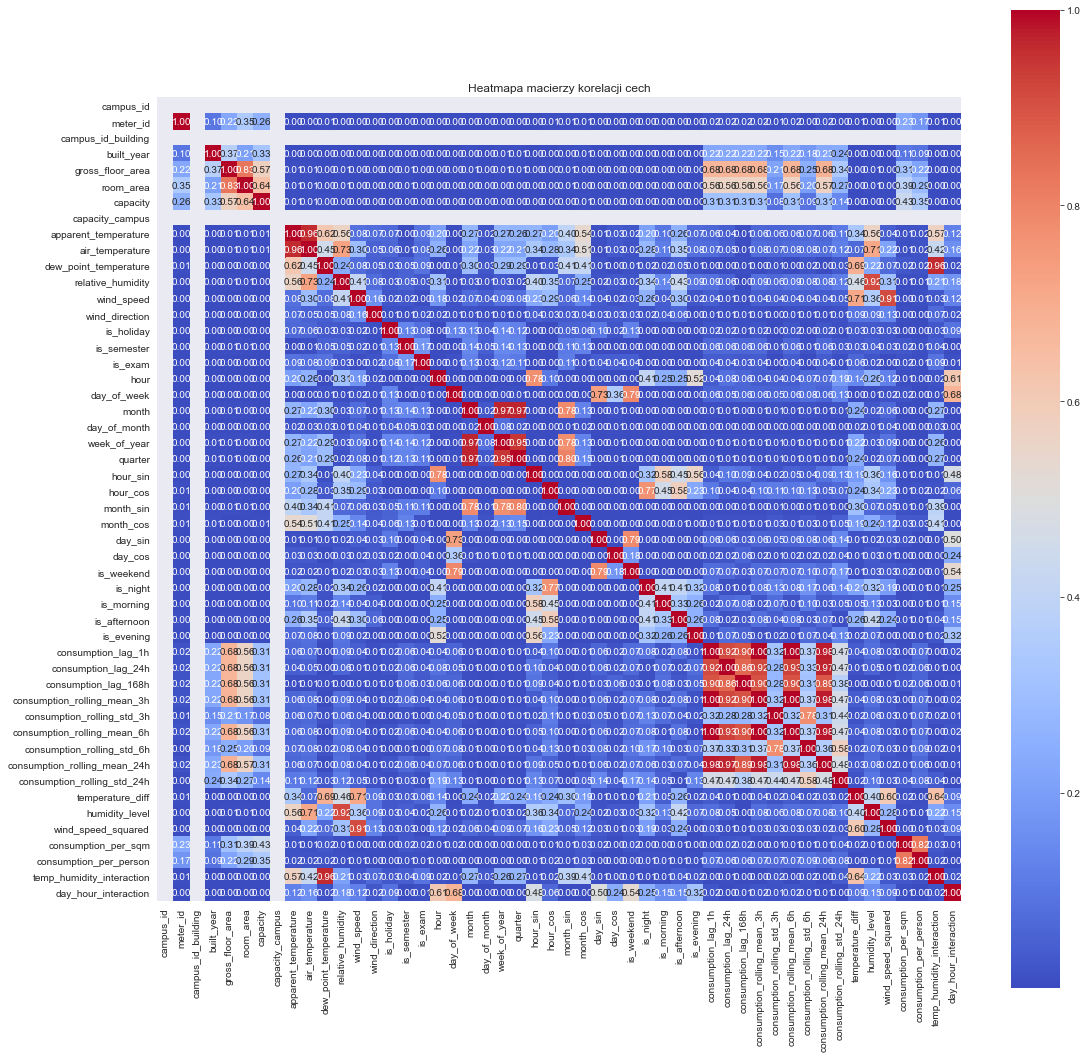

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Macierz korelacji cech
corr_matrix = features.corr().abs()

# Rysowanie heatmapy
plt.figure(figsize=(18, 18))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Heatmapa macierzy korelacji cech")
plt.show()

In [9]:
# Wybierz górny trójkąt macierzy korelacji, by uniknąć powtórzeń i diagonalnych 1.0
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Kolumny o korelacji wyższej niż próg (np. 0.9)
threshold = 0.9
to_pca = [col for col in upper.columns if any(upper[col] > threshold)]

print(f"Liczba cech do pca (korelacja > {threshold}): {len(to_pca)}")
print(to_pca)


Liczba cech do pca (korelacja > 0.9): 10
['air_temperature', 'week_of_year', 'quarter', 'consumption_lag_24h', 'consumption_rolling_mean_3h', 'consumption_rolling_mean_6h', 'consumption_rolling_mean_24h', 'humidity_level', 'wind_speed_squared', 'temp_humidity_interaction']


## Redukcja wymiarowosci

In [34]:
dfwithfeatures_reduced

,campus_id,meter_id,timestamp,consumption,campus_id_building,built_year,category,gross_floor_area,room_area,capacity,...,is_evening,consumption_lag_1h,consumption_lag_168h,consumption_rolling_std_3h,consumption_rolling_std_6h,consumption_rolling_std_24h,temperature_diff,consumption_per_sqm,consumption_per_person,day_hour_interaction
122422,1,4,2018-01-02 18:15:00,3.26000,1,1967.0,mixed use,145558.14,1790.17,79.0,...,1,3.39800,3.60000,0.115764,0.451346,2.486026,-4.6,0.000022,0.041266,18
122423,1,4,2018-01-02 18:30:00,3.25700,1,1967.0,mixed use,145558.14,1790.17,79.0,...,1,3.26000,3.84600,0.080554,0.322523,2.562520,-2.5,0.000022,0.041228,18
122424,1,4,2018-01-02 18:45:00,3.28800,1,1967.0,mixed use,145558.14,1790.17,79.0,...,1,3.25700,4.09900,0.017098,0.178135,2.636028,-3.2,0.000023,0.041620,18
122425,1,4,2018-01-02 19:00:00,3.62600,1,1967.0,mixed use,145558.14,1790.17,79.0,...,1,3.28800,3.95100,0.204681,0.148781,2.670439,-3.2,0.000025,0.045899,19
122426,1,4,2018-01-02 19:15:00,3.88200,1,1967.0,mixed use,145558.14,1790.17,79.0,...,1,3.62600,3.95800,0.297942,0.252934,2.671523,-2.5,0.000027,0.049139,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8070625,1,64,2021-06-30 00:15:00,0.70313,1,1899.0,other,5233.40,253.33,0.0,...,0,0.67188,0.73438,0.190086,0.130511,0.203751,-2.4,0.000134,703130.000000,0
8070627,1,64,2021-06-30 00:45:00,0.70313,1,1899.0,other,5233.40,253.33,0.0,...,0,0.73438,0.70313,0.018042,0.129099,0.199672,-2.5,0.000134,703130.000000,0
8070629,1,64,2021-06-30 01:15:00,0.68750,1,1899.0,other,5233.40,253.33,0.0,...,0,0.70313,0.71875,0.009024,0.020769,0.204189,-2.4,0.000131,687500.000000,2
8070631,1,64,2021-06-30 01:45:00,0.70313,1,1899.0,other,5233.40,253.33,0.0,...,0,0.73438,0.71875,0.023870,0.019138,0.138220,-0.8,0.000134,703130.000000,2


In [58]:
target_col = "consumption"

target_pochodne = ['consumption_lag_1h',
       'consumption_lag_168h', 'consumption_rolling_std_3h',
       'consumption_rolling_std_6h', 'consumption_rolling_std_24h',
       'consumption_per_sqm', 'consumption_per_person']

id_cols = ["campus_id",
           "meter_id",
           "campus_id_building"]


In [72]:
---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
<ipython-input-21-0bb9f41878ac> in <module>
----> 1 components_df = pd.DataFrame(
      2     data=pca.components_,
      3     columns=df_with_features[to_pca],
      4 ).T  # transpozycja dla lepszego odczytu - teraz cechy w wierszach
      5

NameError: name 'pd' is not defined

['air_temperature',
 'week_of_year',
 'quarter',
 'consumption_lag_24h',
 'consumption_rolling_mean_3h',
 'consumption_rolling_mean_6h',
 'consumption_rolling_mean_24h',
 'humidity_level',
 'wind_speed_squared',
 'temp_humidity_interaction',
 'pca_4']

In [11]:
X_pca = df_with_features[to_pca]

In [13]:
X_pca

,air_temperature,week_of_year,quarter,consumption_lag_24h,consumption_rolling_mean_3h,consumption_rolling_mean_6h,consumption_rolling_mean_24h,humidity_level,wind_speed_squared,temp_humidity_interaction
122422,20.5,1,1,7.96900,3.382667,3.731833,7.142500,2,670.81,11.480
122423,20.0,1,1,9.30800,3.305000,3.535667,6.890375,2,219.04,11.400
122424,19.7,1,1,8.62300,3.268333,3.401000,6.668083,2,338.56,11.426
122425,19.4,1,1,8.66700,3.390333,3.386500,6.458042,2,338.56,11.446
122426,19.0,1,1,8.80200,3.598667,3.451833,6.253042,2,219.04,11.590
...,...,...,...,...,...,...,...,...,...,...
8070625,7.6,26,2,0.34375,0.796880,0.752608,0.854821,3,88.36,7.524
8070627,7.2,26,2,0.93750,0.713547,0.755213,0.850915,3,88.36,7.128
8070629,6.2,26,2,0.89063,0.697920,0.700525,0.837243,3,57.76,6.200
8070631,6.5,26,2,0.89063,0.708337,0.710942,0.795576,3,0.00,6.500


In [14]:
save_processed_data(X_pca, "data/processed/features_data_pca.csv")

✓ Dane zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data_pca.csv


In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

In [16]:
pca = PCA(n_components=0.95, random_state=42)  # albo konkretna liczba składowych
X_pca_transformed = pca.fit_transform(X_scaled)

In [26]:
components_df = pd.DataFrame(
    data=pca.components_,
    columns=X_pca.columns
).T  # transpozycja dla lepszego odczytu - teraz cechy w wierszach

print("Macierz komponentów PCA (cechy × komponenty):")
print(components_df)


Macierz komponentów PCA (cechy × komponenty):
                                     0         1         2         3         4
air_temperature               0.069546  0.421660  0.491385  0.268390 -0.257714
week_of_year                 -0.016545 -0.574735  0.270460  0.294639 -0.087883
quarter                      -0.016258 -0.572622  0.272042  0.292264 -0.120855
consumption_lag_24h           0.486905 -0.037516 -0.057517  0.008101  0.003563
consumption_rolling_mean_3h   0.498646 -0.031517 -0.032825 -0.000867  0.008458
consumption_rolling_mean_6h   0.500360 -0.031094 -0.031533 -0.000885  0.008159
consumption_rolling_mean_24h  0.503049 -0.032376 -0.037167  0.002016  0.005766
humidity_level               -0.068984 -0.198509 -0.632663  0.292280  0.315369
wind_speed_squared            0.025289  0.033049  0.435892 -0.017442  0.898489
temp_humidity_interaction     0.009141  0.345070 -0.119826  0.818495  0.065795


In [28]:
# dodajemy składowe główne do ramki
for i in range(X_pca_transformed.shape[1]):
    df_with_features[f"pca_{i+1}"] = X_pca_transformed[:, i]

In [49]:
df_with_features.drop(columns=to_pca, inplace=True)

In [50]:
save_processed_data(df_with_features, "data/processed/features_data_pca.csv")

✓ Dane zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data_pca.csv


In [51]:
save_processed_data(df_with_features.head(4000), "data/processed/sample_pca.csv")

✓ Dane zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\sample_pca.csv


## Feature selection

In [59]:
cat_cols = ["category",
            "name",
            "quarter",]

In [60]:
df_encoded = encode_categorical_features(df_with_features, cat_cols)

KeyError: "['quarter'] not in index"

In [62]:
df_encoded.drop(columns=id_cols, inplace=True)

In [64]:
save_processed_data(df_encoded, "data/processed/features_data_encoded.csv")

✓ Dane zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data_encoded.csv
